In [8]:
# Install dependencies if running in Colab / fresh environment
!pip install torchvision matplotlib seaborn scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 2.3 MB/s eta 0:00:002.3 MB/s eta 0:00:01


In [9]:
"""
Plant Disease Classification using Pretrained CNN (ResNet18)
Dataset: PlantVillage
Author: Kumarkhaniya Aditya
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import confusion_matrix, classification_report

In [10]:
class Config:
    """
    Configuration class that stores all hyperparameters
    and important paths used in the program.
    """

    dataset_path = "PlantVillage"

    image_size = 224
    batch_size = 32
    epochs = 5
    learning_rate = 0.001

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class DatasetAnalyzer:
    """
    Performs basic analysis of the dataset such as
    counting number of images per class.
    """

    def __init__(self, dataset_path):
        self.dataset_path = dataset_path

    def plot_class_distribution(self):
        """
        Plot number of images in each class.
        """

        class_counts = {}

        for class_name in os.listdir(self.dataset_path):

            class_path = os.path.join(self.dataset_path, class_name)

            if os.path.isdir(class_path):
                class_counts[class_name] = len(os.listdir(class_path))

        plt.figure(figsize=(12, 6))
        plt.bar(class_counts.keys(), class_counts.values())
        plt.xticks(rotation=90)
        plt.title("PlantVillage Dataset Distribution")
        plt.xlabel("Disease Class")
        plt.ylabel("Number of Images")
        plt.show()


analyzer = DatasetAnalyzer(Config.dataset_path)
analyzer.plot_class_distribution()

In [11]:
class PlantVillageDataset:
    """
    Handles dataset loading and preprocessing.
    """

    def __init__(self, dataset_path):
        self.dataset_path = dataset_path

        # Image preprocessing pipeline
        self.transform = transforms.Compose([
            transforms.Resize((Config.image_size, Config.image_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def load_data(self):
        """
        Load dataset using ImageFolder and create
        training and validation loaders.
        """

        dataset = datasets.ImageFolder(
            root=self.dataset_path,
            transform=self.transform
        )

        train_size = int(0.8 * len(dataset))
        val_size = len(dataset) - train_size

        train_dataset, val_dataset = random_split(
            dataset,
            [train_size, val_size]
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=Config.batch_size,
            shuffle=True
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=Config.batch_size,
            shuffle=False
        )

        return train_loader, val_loader, dataset.classes


dataset_loader = PlantVillageDataset(Config.dataset_path)
train_loader, val_loader, classes = dataset_loader.load_data()

print("Number of classes:", len(classes))

Number of classes: 15


In [13]:
class PlantDiseaseModel(nn.Module):
    """
    CNN model based on pretrained ResNet18.
    
    Layer Explanation:
    
    1. Convolution Layers (ResNet backbone)
       - Extract spatial features such as edges,
         textures and patterns from leaf images.
    
    2. Batch Normalization
       - Stabilizes training and speeds convergence.
    
    3. Residual Connections
       - Allow deep networks to train efficiently
         without vanishing gradient problems.
    
    4. Fully Connected Layer
       - Maps extracted features to plant disease classes.
    """

    def __init__(self, num_classes):
        super().__init__()

        # Load pretrained model
        self.model = models.resnet18(pretrained=True)

        # Freeze convolution layers
        for param in self.model.parameters():
            param.requires_grad = False

        # Replace final classification layer
        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )

    def forward(self, x):
        return self.model(x)


model = PlantDiseaseModel(len(classes)).to(Config.device)
print(model)

/home/aditya/miniconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/aditya/miniconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


PlantDiseaseModel(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, t

In [14]:
class Trainer:
    """
    Handles training and validation of the model.
    """

    def __init__(self, model, train_loader, val_loader):

        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(
            model.parameters(),
            lr=Config.learning_rate
        )

        self.train_losses = []
        self.val_losses = []
        self.train_acc = []
        self.val_acc = []

    def train_epoch(self):

        self.model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in self.train_loader:

            images = images.to(Config.device)
            labels = labels.to(Config.device)

            self.optimizer.zero_grad()

            outputs = self.model(images)
            loss = self.criterion(outputs, labels)

            loss.backward()
            self.optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        return running_loss / len(self.train_loader), accuracy

    def validate(self):

        self.model.eval()

        running_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in self.val_loader:

                images = images.to(Config.device)
                labels = labels.to(Config.device)

                outputs = self.model(images)

                loss = self.criterion(outputs, labels)

                running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        return running_loss / len(self.val_loader), accuracy

    def train(self):

        for epoch in range(Config.epochs):

            train_loss, train_acc = self.train_epoch()
            val_loss, val_acc = self.validate()

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)

            self.train_acc.append(train_acc)
            self.val_acc.append(val_acc)

            print(f"Epoch {epoch+1}/{Config.epochs}")
            print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}")
            print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}")
            print()


trainer = Trainer(model, train_loader, val_loader)
trainer.train()

Epoch 1/5
Train Loss: 0.8254 | Train Acc: 78.10
Val Loss: 0.4203 | Val Acc: 88.66

Epoch 2/5
Train Loss: 0.3795 | Train Acc: 89.24
Val Loss: 0.2982 | Val Acc: 91.30

Epoch 3/5
Train Loss: 0.3037 | Train Acc: 91.05
Val Loss: 0.2487 | Val Acc: 92.49

Epoch 4/5
Train Loss: 0.2602 | Train Acc: 92.17
Val Loss: 0.2209 | Val Acc: 93.51

Epoch 5/5
Train Loss: 0.2383 | Train Acc: 92.74
Val Loss: 0.2121 | Val Acc: 93.39



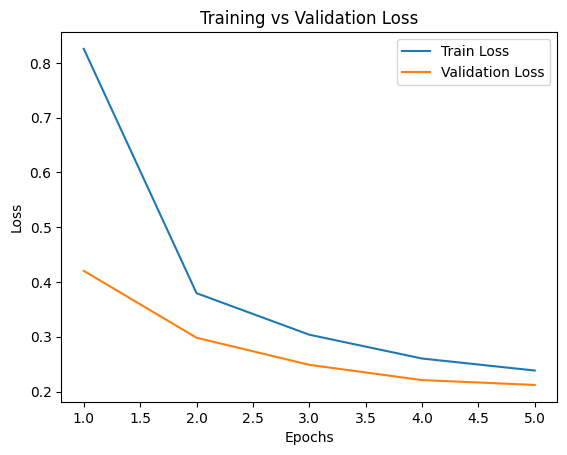

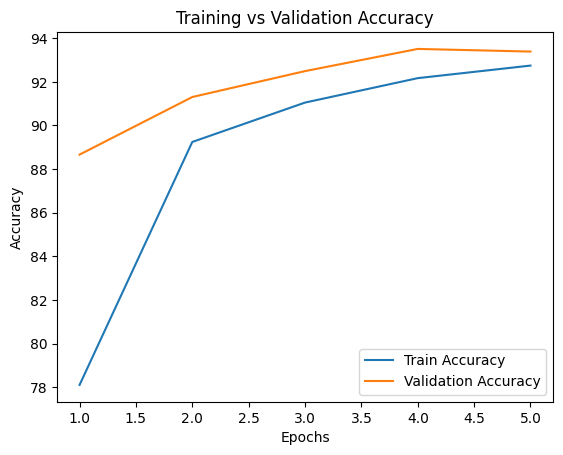

In [15]:
def plot_training_graphs(trainer):

    epochs = range(1, len(trainer.train_losses) + 1)

    plt.figure()

    plt.plot(epochs, trainer.train_losses, label="Train Loss")
    plt.plot(epochs, trainer.val_losses, label="Validation Loss")

    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()

    plt.show()

    plt.figure()

    plt.plot(epochs, trainer.train_acc, label="Train Accuracy")
    plt.plot(epochs, trainer.val_acc, label="Validation Accuracy")

    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title("Training vs Validation Accuracy")
    plt.legend()

    plt.show()


plot_training_graphs(trainer)

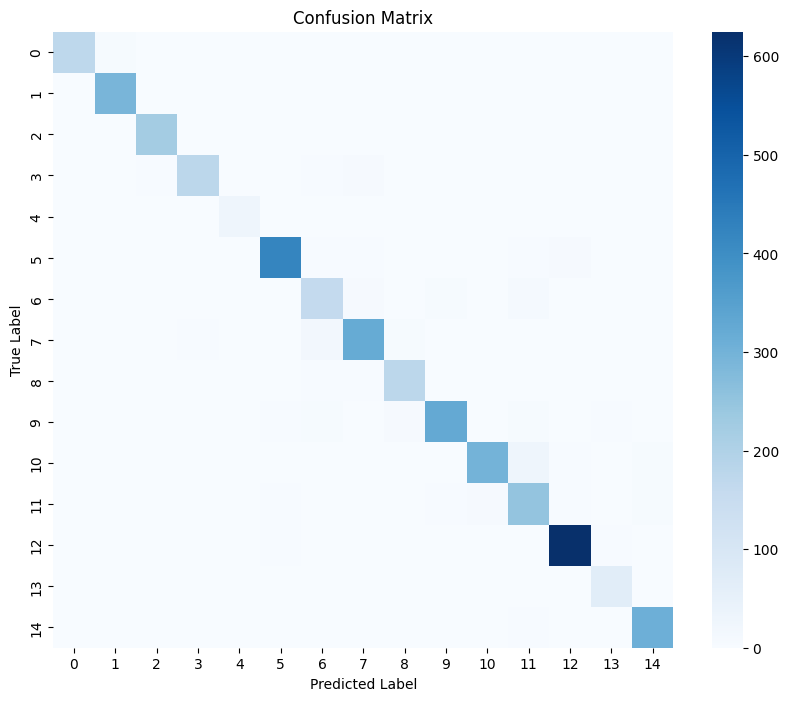

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       181
           1       0.97      0.98      0.98       297
           2       0.96      1.00      0.98       225
           3       0.96      0.91      0.94       194
           4       0.97      0.91      0.94        33
           5       0.97      0.94      0.96       446
           6       0.81      0.82      0.82       196
           7       0.91      0.89      0.90       363
           8       0.90      0.93      0.92       192
           9       0.95      0.90      0.93       363
          10       0.95      0.87      0.91       342
          11       0.83      0.90      0.86       278
          12       0.96      0.98      0.97       636
          13       0.86      0.99      0.92        70
          14       0.95      0.99      0.97       312

    accuracy                           0.93      4128
   macro avg       0.93      0.93      0.93      4128
weighted avg       0.93   

In [16]:
def evaluate_model(model, val_loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(Config.device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, cmap="Blues")

    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.show()

    print(classification_report(all_labels, all_preds))


evaluate_model(model, val_loader)